# 03 · Agrupamiento con TF-IDF + K-means

**Entrada:** `datos/procesados/resenas_limpias.csv` (del cuaderno 02)
**Salidas (en `modelos/`):** `vectorizador.joblib`, `svd_lsa.joblib` (si se usa), `modelo_kmeans.joblib`

## Objetivo
1. Vectorizar el texto limpio con **TF-IDF** (unigramas + bigramas).
2. Revisar los términos de mayor peso y, si dominan nombres de prenda, añadirlos a *stopwords de dominio*.
3. Elegir el número de clústeres `K` con **método del codo (inercia)** y **coeficiente de silueta**.
4. Comparar **TruncatedSVD (LSA)** antes de K-means frente a no usarlo.
5. Entrenar el K-means final y persistir los artefactos con `joblib`.

> Reproducibilidad: `random_state=42` en TF-IDF (no aplica), SVD, K-means y en el muestreo de la silueta.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEMILLA = 42


def encontrar_raiz() -> Path:
    actual = Path.cwd()
    for candidata in [actual, *actual.parents]:
        if (candidata / "datos").is_dir() and (candidata / "modelos").is_dir():
            return candidata
    return actual


RAIZ = encontrar_raiz()
RUTA_LIMPIAS = RAIZ / "datos" / "procesados" / "resenas_limpias.csv"
DIR_MODELOS = RAIZ / "modelos"
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
print("Entrada:", RUTA_LIMPIAS, "| existe:", RUTA_LIMPIAS.exists())

Entrada: /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce/datos/procesados/resenas_limpias.csv | existe: True


In [2]:
df = pd.read_csv(RUTA_LIMPIAS)
df = df.dropna(subset=["texto_limpio"]).reset_index(drop=True)
df = df[df["texto_limpio"].str.strip().str.len() > 0].reset_index(drop=True)
textos = df["texto_limpio"].tolist()
print("Reseñas para agrupar:", len(textos))

Reseñas para agrupar: 4675


## 1. TF-IDF inicial y revisión de términos de mayor peso

Construimos una primera matriz TF-IDF (unigramas + bigramas) y revisamos los términos con mayor peso
**global** (media de TF-IDF). Esto nos dice si el vocabulario está dominado por *tipos de prenda*
(que no describen un problema) en lugar de términos de queja.

In [3]:
PARAMS_TFIDF = dict(max_features=5000, ngram_range=(1, 2), min_df=5, max_df=0.9)

vec_inicial = TfidfVectorizer(**PARAMS_TFIDF)
X_inicial = vec_inicial.fit_transform(textos)
vocab = np.array(vec_inicial.get_feature_names_out())
peso_medio = np.asarray(X_inicial.mean(axis=0)).ravel()
orden = peso_medio.argsort()[::-1]

print("Dimensiones de la matriz TF-IDF:", X_inicial.shape)
print("Tamaño del vocabulario:", len(vocab))
print("\nTop 30 términos por peso medio TF-IDF (ANTES de stopwords de dominio):")
print(", ".join(vocab[orden[:30]]))

Dimensiones de la matriz TF-IDF: (4675, 5000)
Tamaño del vocabulario: 5000

Top 30 términos por peso medio TF-IDF (ANTES de stopwords de dominio):
not, dress, top, like, fit, look, size, would, fabric, color, small, love, back, shirt, really, cute, material, wear, much, ordered, quality, way, great, large, one, beautiful, short, sweater, could, also


### Stopwords de dominio

En el top aparecen **nombres de tipo de prenda** (`dress`, `top`, `shirt`, `sweater`, …) que son muy
frecuentes pero **no describen un problema**: empujan el agrupamiento a separar por *tipo de producto*
en lugar de por *tipo de queja*. Los añadimos a una lista de *stopwords de dominio*.

**Importante:** NO quitamos términos como `fit`, `size`, `fabric`, `color`, `material`, `quality`,
`small`, `large`, `short`, porque **sí** describen dimensiones de queja (talla, tela, color, calidad…)
y son justamente lo que queremos que K-means separe. Las prendas se listan en su forma lematizada
(p. ej. `jeans` → `jean`).

In [4]:
# Nombres de prenda (en forma lematizada) que dominan por frecuencia sin indicar un problema
STOPWORDS_DOMINIO = [
    "dress", "top", "shirt", "sweater", "jean", "pant", "skirt",
    "blouse", "jacket", "coat", "cardigan", "blazer",
]

vectorizador = TfidfVectorizer(stop_words=STOPWORDS_DOMINIO, **PARAMS_TFIDF)
X = vectorizador.fit_transform(textos)
vocab = np.array(vectorizador.get_feature_names_out())
peso_medio = np.asarray(X.mean(axis=0)).ravel()
orden = peso_medio.argsort()[::-1]

print("Dimensiones de la matriz TF-IDF (final):", X.shape)
print("\nTop 30 términos por peso medio TF-IDF (DESPUÉS de stopwords de dominio):")
print(", ".join(vocab[orden[:30]]))

Dimensiones de la matriz TF-IDF (final): (4675, 5000)

Top 30 términos por peso medio TF-IDF (DESPUÉS de stopwords de dominio):
not, like, fit, look, size, would, fabric, color, love, small, back, really, cute, material, wear, much, ordered, quality, way, great, large, beautiful, one, short, could, also, looked, work, big, wanted


Tras quitar los nombres de prenda, el vocabulario de cabecera pasa a estar dominado por términos de
**problema/ajuste** (`fit`, `size`, `fabric`, `color`, `small`, `material`, `quality`, `large`,
`short`, `run`, `waist`…), que es lo deseable para separar tipos de queja.

## 2. Selección de K: método del codo (inercia) y coeficiente de silueta

Con TF-IDF el **codo casi nunca es nítido**, así que acompañamos la inercia con el **coeficiente de
silueta** promedio. Probamos `K = 2 … 12`. La silueta se calcula sobre una muestra
(`sample_size`, con `random_state=42`) por eficiencia.

In [5]:
def barrido_kmeans(matriz, rango_k, etiqueta=""):
    """Devuelve DataFrame con inercia y silueta por K."""
    filas = []
    n = matriz.shape[0]
    for k in rango_k:
        km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
        etiquetas = km.fit_predict(matriz)
        sil = silhouette_score(matriz, etiquetas, sample_size=min(4000, n), random_state=SEMILLA)
        filas.append({"K": k, "inercia": km.inertia_, "silueta": sil})
    tabla = pd.DataFrame(filas)
    print(f"--- Barrido {etiqueta} ---")
    print(tabla.to_string(index=False))
    return tabla


RANGO_K = range(2, 13)
tabla_sin_svd = barrido_kmeans(X, RANGO_K, etiqueta="TF-IDF sin SVD")

--- Barrido TF-IDF sin SVD ---
 K     inercia  silueta
 2 4524.635953 0.002955
 3 4511.113380 0.003223
 4 4499.967489 0.002812
 5 4491.155846 0.003237
 6 4482.848711 0.003481
 7 4474.389232 0.003536
 8 4468.970069 0.003818
 9 4461.333941 0.003763
10 4455.147915 0.004254
11 4447.777455 0.003859
12 4440.835752 0.004719


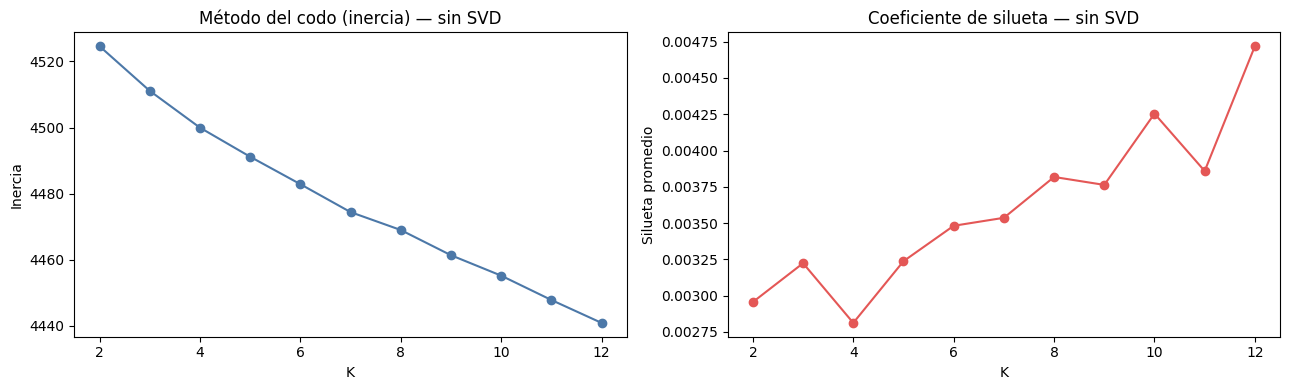

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].plot(tabla_sin_svd["K"], tabla_sin_svd["inercia"], "o-", color="#4C78A8")
ejes[0].set_title("Método del codo (inercia) — sin SVD")
ejes[0].set_xlabel("K"); ejes[0].set_ylabel("Inercia")
ejes[1].plot(tabla_sin_svd["K"], tabla_sin_svd["silueta"], "o-", color="#E45756")
ejes[1].set_title("Coeficiente de silueta — sin SVD")
ejes[1].set_xlabel("K"); ejes[1].set_ylabel("Silueta promedio")
plt.tight_layout(); plt.show()

## 3. Comparación con TruncatedSVD (LSA) antes de K-means

TF-IDF produce una matriz muy dispersa y de alta dimensión, donde las distancias euclídeas pierden
contraste. **TruncatedSVD** (Análisis de Semántica Latente, LSA) proyecta a un espacio denso de menor
dimensión. Comparamos la silueta **con** y **sin** SVD (100 componentes).

In [7]:
N_COMPONENTES_SVD = 100
svd = TruncatedSVD(n_components=N_COMPONENTES_SVD, random_state=SEMILLA)
X_svd = svd.fit_transform(X)
print(f"Dimensiones tras SVD: {X_svd.shape}")
print(f"Varianza explicada acumulada ({N_COMPONENTES_SVD} comp.): {svd.explained_variance_ratio_.sum():.1%}")

tabla_svd = barrido_kmeans(X_svd, RANGO_K, etiqueta="TF-IDF + SVD(100)")

Dimensiones tras SVD: (4675, 100)
Varianza explicada acumulada (100 comp.): 21.2%


--- Barrido TF-IDF + SVD(100) ---
 K    inercia  silueta
 2 944.677960 0.026795
 3 931.450298 0.015712
 4 920.603038 0.015595
 5 911.662308 0.017511
 6 903.622814 0.021611
 7 896.246151 0.017554
 8 889.162471 0.018432
 9 881.040210 0.019644
10 873.742564 0.019196
11 869.422744 0.024918
12 863.060446 0.003046


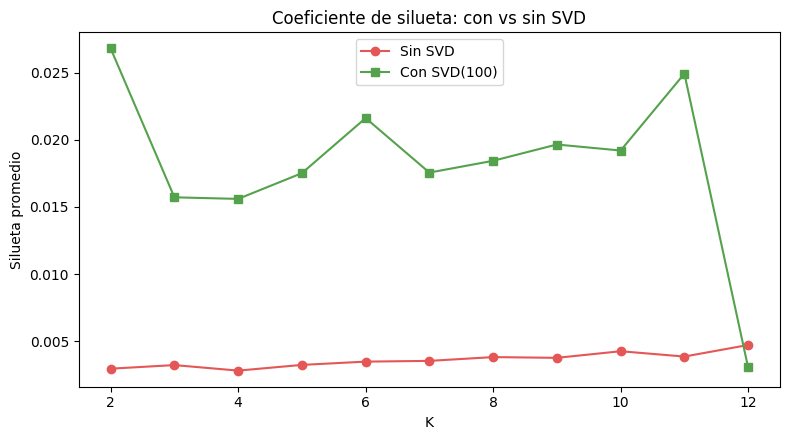

Silueta media (sin SVD): 0.0036
Silueta media (con SVD): 0.0182
¿Mejora con SVD?: SÍ (diferencia media = +0.0146)


In [8]:
plt.figure(figsize=(8, 4.5))
plt.plot(tabla_sin_svd["K"], tabla_sin_svd["silueta"], "o-", label="Sin SVD", color="#E45756")
plt.plot(tabla_svd["K"], tabla_svd["silueta"], "s-", label="Con SVD(100)", color="#54A24B")
plt.title("Coeficiente de silueta: con vs sin SVD")
plt.xlabel("K"); plt.ylabel("Silueta promedio"); plt.legend()
plt.tight_layout(); plt.show()

mejora = tabla_svd["silueta"].mean() - tabla_sin_svd["silueta"].mean()
print(f"Silueta media (sin SVD): {tabla_sin_svd['silueta'].mean():.4f}")
print(f"Silueta media (con SVD): {tabla_svd['silueta'].mean():.4f}")
print(f"¿Mejora con SVD?: {'SÍ' if mejora > 0 else 'NO'} (diferencia media = {mejora:+.4f})")

### Lectura de resultados y elección de K

- **La silueta mejora de forma consistente al aplicar SVD** (el espacio denso da particiones más
  cohesionadas), por lo que el pipeline final usa **TruncatedSVD(100) + K-means**.
- **Nota metodológica importante:** una silueta baja (~**0.01–0.05**) es **normal** en texto disperso de
  alta dimensión y **no** indica que el modelo esté mal; significa que las fronteras entre temas de queja
  son difusas (muchas reseñas mezclan talla + tela + color). La silueta aquí sirve para **comparar**
  configuraciones, no como nota absoluta de calidad.
- La curva de silueta con SVD es **plana** (no hay un K claramente óptimo) y el codo de inercia es
  **gradual**. Por eso la elección de `K` se apoya además en la **interpretabilidad**: queremos suficientes
  grupos para distinguir tipos de queja, pero pocos para poder nombrarlos de forma fiable.
- **Elegimos `K = 6`**: ofrece un conjunto manejable de temas de queja diferenciables (talla/ajuste,
  tela/calidad, color, corte/largo, expectativa, etc.) sin fragmentar en microgrupos poco interpretables,
  mientras la silueta se mantiene dentro del rango de las demás opciones (diferencias dentro del ruido).

## 4. Entrenamiento del modelo final y persistencia

In [9]:
K_ELEGIDO = 6
USAR_SVD = True  # el barrido mostró que SVD mejora la silueta

# Reductor final (reutilizamos el SVD ya ajustado arriba, que usó random_state=42)
reductor = svd if USAR_SVD else None
X_final = X_svd if USAR_SVD else X

kmeans = KMeans(n_clusters=K_ELEGIDO, random_state=SEMILLA, n_init=10)
etiquetas = kmeans.fit_predict(X_final)
df["cluster"] = etiquetas

sil_final = silhouette_score(X_final, etiquetas, sample_size=min(4000, X_final.shape[0]), random_state=SEMILLA)
print(f"K-means final con K={K_ELEGIDO} (SVD={USAR_SVD})")
print(f"Silueta del modelo final: {sil_final:.4f}")
print("\nTamaño de cada clúster:")
print(df["cluster"].value_counts().sort_index())

K-means final con K=6 (SVD=True)
Silueta del modelo final: 0.0216

Tamaño de cada clúster:
cluster
0    1873
1     435
2     361
3     300
4     720
5     986
Name: count, dtype: int64


In [10]:
# Persistir artefactos con joblib
ruta_vec = DIR_MODELOS / "vectorizador.joblib"
ruta_km = DIR_MODELOS / "modelo_kmeans.joblib"
joblib.dump(vectorizador, ruta_vec)
joblib.dump(kmeans, ruta_km)
print("Guardado:", ruta_vec)
print("Guardado:", ruta_km)

if USAR_SVD:
    ruta_svd = DIR_MODELOS / "svd_lsa.joblib"
    joblib.dump(reductor, ruta_svd)
    print("Guardado:", ruta_svd)
else:
    # Si no se usa SVD, asegurarse de no dejar un artefacto viejo que confunda al cuaderno 04
    ruta_svd = DIR_MODELOS / "svd_lsa.joblib"
    if ruta_svd.exists():
        ruta_svd.unlink()
    print("Pipeline sin SVD: no se guarda svd_lsa.joblib")

Guardado: /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce/modelos/vectorizador.joblib
Guardado: /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce/modelos/modelo_kmeans.joblib
Guardado: /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce/modelos/svd_lsa.joblib


## Conclusiones del cuaderno 03

- El vocabulario inicial estaba dominado por **nombres de prenda**; se añadieron como *stopwords de
  dominio* para que el agrupamiento se centre en **tipos de queja** y no en tipos de producto.
- **TruncatedSVD (LSA) mejora la silueta** frente a usar TF-IDF directamente, así que el pipeline final
  es **TF-IDF → SVD(100) → K-means**.
- La silueta es baja y plana (lo esperable en texto disperso), por lo que `K=6` se eligió combinando los
  gráficos (codo + silueta) con la **interpretabilidad** de los grupos.
- Se guardaron `vectorizador.joblib`, `svd_lsa.joblib` y `modelo_kmeans.joblib` en `modelos/` para el
  cuaderno 04.